# EDA — Auto MPG

## Princípio Estrutural da EDA

Entender a "anatomia" dos dados:

| Dimensão | Tipos de Dados | Dados Faltantes | Duplicadas |
|---|---|---|---|
| `df.shape` / `df.info()` | `df.dtypes` | `df.isna()` | `df.duplicated()` |

Dataset: **Auto MPG** importado direto da UCI via `ucimlrepo` (`id=9`) — 398 instâncias, versão de Quinlan 1993 (StatLib / CMU).

In [1]:
# Garante o ucimlrepo instalado no kernel atual (força o pip install antes de rodar o resto)
%pip install -q ucimlrepo

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\gusta\Documents\AVD-2026-2\AVD-20262-pratica-streamlit-Auto-MPG\.venv\Scripts\python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

## Carregar o dataset

O dataset é importado **direto da UCI** com o pacote `ucimlrepo` (`fetch_ucirepo(id=9)`) — sem depender do arquivo local `auto-mpg.data`.

A API devolve os dados já separados em `features` / `targets` / `ids`. Usamos `auto_mpg.data.original`, que junta tudo num único DataFrame, e apenas:

- reordenamos as colunas no layout clássico (`mpg` primeiro, `car_name` por último);
- convertemos `weight` para `float64` (a API entrega como inteiro);
- trocamos as vírgulas de `car_name` por espaços (a API separa os tokens do nome por vírgula).

Os 6 valores ausentes de `horsepower` já vêm como `NaN`.

> Requer o pacote: `pip install ucimlrepo`

In [3]:
from ucimlrepo import fetch_ucirepo

# Auto MPG — id=9 no repositório da UCI (StatLib / CMU, versão de Quinlan, 1993)
auto_mpg = fetch_ucirepo(id=9)

# DataFrame completo: features + target + identificador (car_name)
df = auto_mpg.data.original.copy()

# layout clássico: target primeiro, identificador por último
cols = [
    "mpg",
    "cylinders",
    "displacement",
    "horsepower",
    "weight",
    "acceleration",
    "model_year",
    "origin",
    "car_name",
]
df = df[cols]

# ajustes para bater com a versão canônica do StatLib
df["weight"] = df["weight"].astype("float64")                       # a API entrega como int
df["car_name"] = df["car_name"].str.replace(",", " ", regex=False)  # a API separa tokens por vírgula

df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


In [4]:
# Metadados e dicionário de variáveis fornecidos pela UCI
print(auto_mpg.metadata["abstract"], "\n")
auto_mpg.variables[["name", "role", "type", "description", "units"]]

Revised from CMU StatLib library, data concerns city-cycle fuel consumption 



,name,role,type,description,units
0,displacement,Feature,Continuous,None,None
1,mpg,Target,Continuous,None,None
2,cylinders,Feature,Integer,None,None
3,horsepower,Feature,Continuous,None,None
4,weight,Feature,Continuous,None,None
5,acceleration,Feature,Continuous,None,None
6,model_year,Feature,Integer,None,None
7,origin,Feature,Integer,None,None
8,car_name,ID,Categorical,None,None


## 1. Dimensionalidade — `df.shape` / `df.info()`

In [5]:
print(f"Linhas x Colunas: {df.shape}")
print(f"Número de linhas:   {df.shape[0]}")
print(f"Número de colunas:  {df.shape[1]}")
print(f"Total de células:   {df.size}")

Linhas x Colunas: (398, 9)
Número de linhas:   398
Número de colunas:  9
Total de células:   3582


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    float64
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car_name      398 non-null    object 
dtypes: float64(5), int64(3), object(1)
memory usage: 28.1+ KB


## 2. Tipos de dados — `df.dtypes`

In [7]:
df.dtypes

mpg             float64
cylinders         int64
displacement    float64
horsepower      float64
weight          float64
acceleration    float64
model_year        int64
origin            int64
car_name         object
dtype: object

In [8]:
df.dtypes.value_counts()

float64    5
int64      3
object     1
Name: count, dtype: int64

## 3. Dados faltantes (missing values) — `df.isna()`

In [9]:
faltantes = pd.DataFrame({
    "n_faltantes": df.isna().sum(),
    "pct_faltantes": (df.isna().mean() * 100).round(2),
})
faltantes

,n_faltantes,pct_faltantes
mpg,0,0.00
cylinders,0,0.00
displacement,0,0.00
horsepower,6,1.51
weight,0,0.00
acceleration,0,0.00
model_year,0,0.00
origin,0,0.00
car_name,0,0.00


In [10]:
print(f"Total de valores faltantes no dataset: {int(df.isna().sum().sum())}")

# Linhas que possuem algum valor faltante
df[df.isna().any(axis=1)]

Total de valores faltantes no dataset: 6


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
32,25.0,4,98.0,NaN,2046.0,19.0,71,1,ford pinto
126,21.0,6,200.0,NaN,2875.0,17.0,74,1,ford maverick
330,40.9,4,85.0,NaN,1835.0,17.3,80,2,renault lecar deluxe
336,23.6,4,140.0,NaN,2905.0,14.3,80,1,ford mustang cobra
354,34.5,4,100.0,NaN,2320.0,15.8,81,2,renault 18i
374,23.0,4,151.0,NaN,3035.0,20.5,82,1,amc concord dl


## 4. Duplicadas — `df.duplicated()`

In [11]:
print(f"Linhas totalmente duplicadas: {df.duplicated().sum()}")

# Duplicadas ignorando o identificador único 'car_name'
dup_sem_nome = df.drop(columns="car_name").duplicated().sum()
print(f"Duplicadas ignorando 'car_name': {dup_sem_nome}")

# Nomes de carro repetidos
print(f"'car_name' repetidos: {df['car_name'].duplicated().sum()}")

Linhas totalmente duplicadas: 0
Duplicadas ignorando 'car_name': 0
'car_name' repetidos: 93


In [12]:
df[df.duplicated(keep=False)]

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name


## Resumo da anatomia dos dados

In [13]:
resumo = pd.DataFrame({
    "Dimensão": [f"{df.shape[0]} linhas x {df.shape[1]} colunas"],
    "Tipos de Dados": [", ".join(f"{k}: {v}" for k, v in df.dtypes.astype(str).value_counts().items())],
    "Dados Faltantes": [f"{int(df.isna().sum().sum())} células ({df.columns[df.isna().any()].tolist()})"],
    "Duplicadas": [f"{df.duplicated().sum()} linhas"],
})
resumo.T.rename(columns={0: "valor"})

,valor
Dimensão,398 linhas x 9 colunas
Tipos de Dados,"float64: 5, int64: 3, object: 1"
Dados Faltantes,6 células (['horsepower'])
Duplicadas,0 linhas


## Princípio Distribucional

Com a anatomia dos dados mapeada, o próximo passo é olhar como cada variável quantitativa se distribui — ainda com o dataset original (sem tratar ausentes ou outliers). Esse retrato "antes" é o que vai orientar as decisões de tratamento na próxima seção: se uma variável for muito assimétrica, por exemplo, faz mais sentido pensar em mediana do que em média na hora de resumir ou imputar.

In [14]:
VARS_QUANT = ["mpg", "displacement", "horsepower", "weight", "acceleration"]
VARS_QUALI = ["cylinders", "model_year", "origin"]

desc_antes = df[VARS_QUANT].describe().T
desc_antes["skewness"] = df[VARS_QUANT].skew()
desc_antes["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc_antes[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
)

,mean,median,std,min,max,skewness,kurtosis
mpg,23.51,23.0,7.82,9.0,46.6,0.46,-0.51
displacement,193.43,148.5,104.27,68.0,455.0,0.72,-0.75
horsepower,104.47,93.5,38.49,46.0,230.0,1.09,0.70
weight,2970.42,2803.5,846.84,1613.0,5140.0,0.53,-0.79
acceleration,15.57,15.5,2.76,8.0,24.8,0.28,0.42


**Discussão:** `horsepower` é a mais assimétrica (skewness ≈ 1,09) — coerente com o esperado, já que poucos carros têm motores muito potentes, o que puxa a cauda direita. `displacement` (0,72) e `weight` (0,53) seguem o mesmo padrão, com intensidade menor. `mpg` (0,46) e `acceleration` (0,28) são as mais próximas de simétricas. Nenhuma curtose passa de 1 em módulo, então não há indício de caudas muito mais pesadas que a normal — a assimetria é o ponto de atenção aqui, não achatamento/afunilamento extremos.

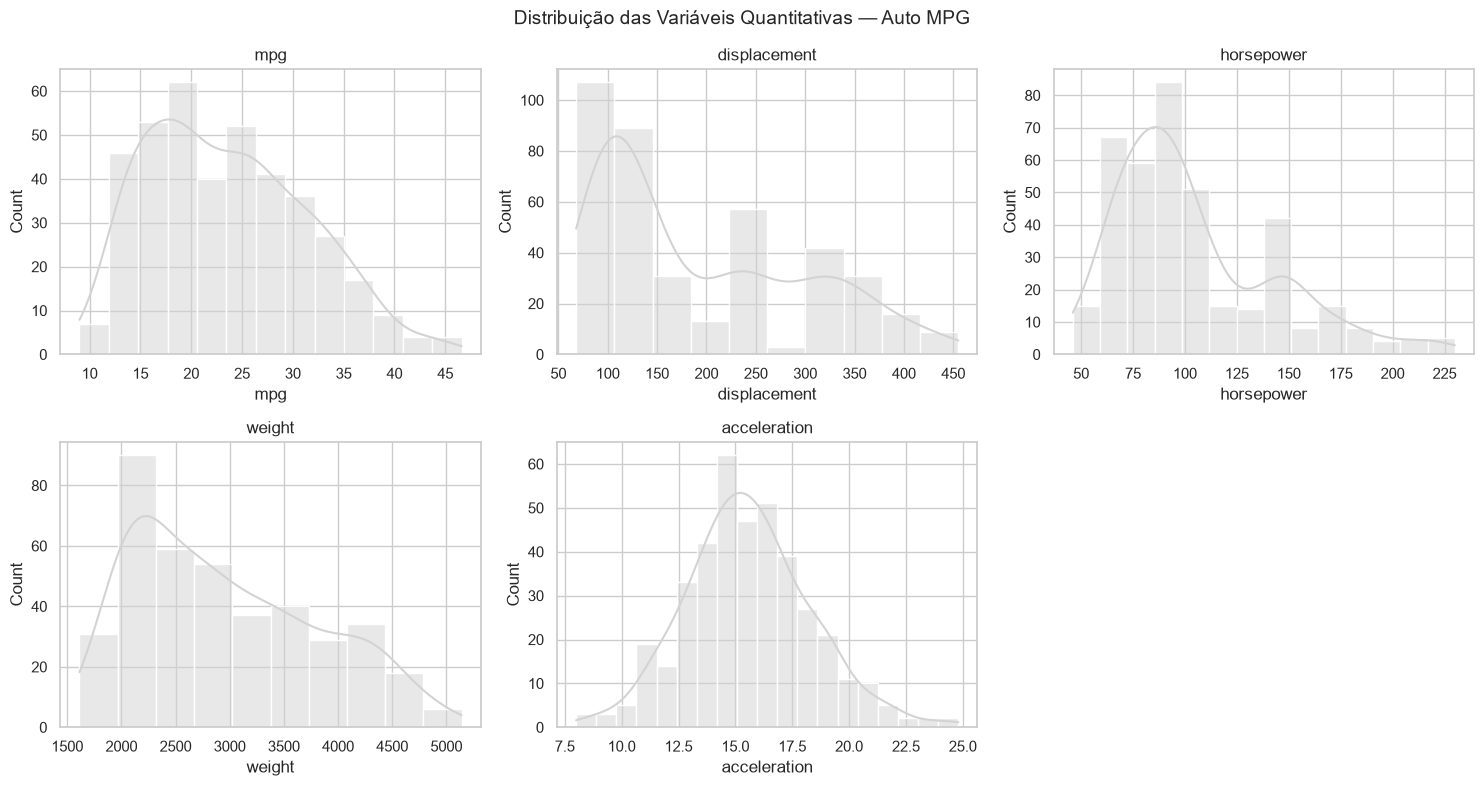

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    sns.histplot(data=df, x=col, kde=True, color="lightgray", ax=axes[i])
    axes[i].set_title(col)

for ax in axes[len(VARS_QUANT):]:
    ax.axis("off")

fig.suptitle("Distribuição das Variáveis Quantitativas — Auto MPG", fontsize=14)
plt.tight_layout()
plt.show()

Visualmente os histogramas confirmam a tabela: `horsepower`, `displacement` e `weight` têm uma cauda à direita claramente mais longa (poucos carros "extremos" puxando o gráfico), enquanto `mpg` e `acceleration` têm um formato mais próximo do simétrico, com um único pico central.

### Dispersão e outliers (visão inicial)

Antes de decidir qualquer tratamento, vale olhar dispersão (variância/desvio-padrão/IQR) e possíveis outliers pela regra do boxplot.

,var,std,IQR
mpg,61.09,7.82,11.50
displacement,10872.20,104.27,157.75
horsepower,1481.57,38.49,51.00
weight,717140.99,846.84,1384.25
acceleration,7.60,2.76,3.35


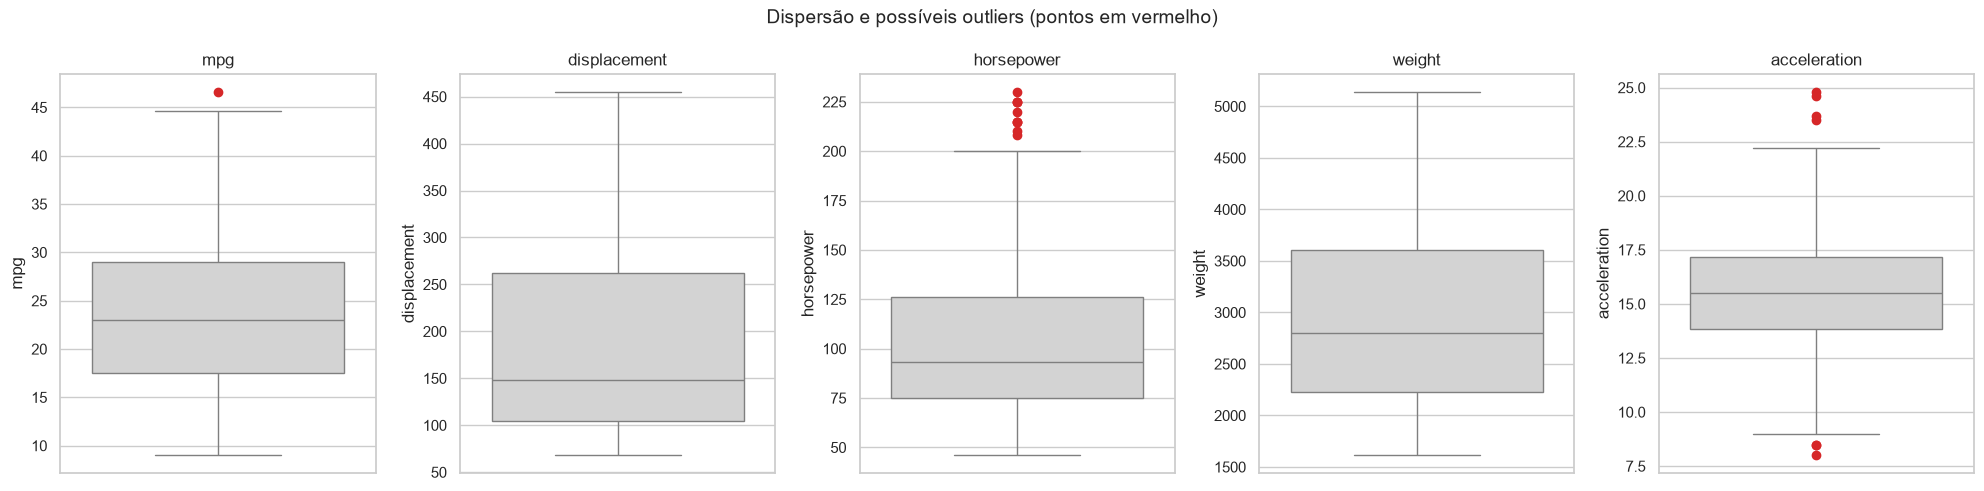

In [16]:
dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)
display(dispersao.round(2))

fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 5))
for i, col in enumerate(VARS_QUANT):
    sns.boxplot(
        data=df, y=col, color="lightgray",
        flierprops=dict(markerfacecolor="tab:red", markeredgecolor="tab:red", marker="o"),
        ax=axes[i],
    )
    axes[i].set_title(col)
fig.suptitle("Dispersão e possíveis outliers (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

### Teste de aderência à normalidade (Shapiro-Wilk)

`horsepower`, `displacement` e `weight` já pareciam bem afastadas de uma normal nos histogramas. Vamos confirmar formalmente com o Shapiro-Wilk (H0: a variável segue distribuição normal) em todas as quantitativas.

In [17]:
from scipy import stats

resultados_shapiro = []
for col in VARS_QUANT:
    stat, p = stats.shapiro(df[col].dropna())
    resultados_shapiro.append({
        "variavel": col,
        "estatistica": round(stat, 4),
        "p_valor": p,
        "rejeita_normalidade": p < 0.05,
    })

pd.DataFrame(resultados_shapiro).set_index("variavel")

,estatistica,p_valor,rejeita_normalidade
variavel,,,
mpg,0.9680,1.183385e-07,True
displacement,0.8804,5.143160e-17,True
horsepower,0.9041,5.022069e-15,True
weight,0.9414,1.970250e-11,True
acceleration,0.9924,3.986944e-02,True


**Discussão:** todas as cinco variáveis rejeitam a hipótese de normalidade (p < 0,05). `mpg`, `displacement`, `horsepower` e `weight` rejeitam com folga (p muito menor que 0,05, coerente com a assimetria alta observada). Já `acceleration` — a mais simétrica na Seção 3 — rejeita por uma margem bem mais estreita (p ≈ 0,04, logo abaixo do corte de 0,05), o que é esperado: mesmo uma assimetria pequena (0,28) é suficiente para rejeitar com n≈398 (amostra grande o bastante para o teste ser sensível a desvios pequenos). Isso reforça a leitura da Seção 3: nenhuma variável aqui deveria ser tratada como normal em técnicas que dependem dessa premissa.

## Tratamento de Dados Ausentes e Outliers

A EDA não é uma linha reta: agora que já vimos o retrato estatístico "antes" (distribuição, dispersão, normalidade), temos a informação que faltava para decidir como tratar os 6 valores ausentes de `horsepower` (Seção 3) e os possíveis outliers das variáveis quantitativas. Depois do tratamento, repetimos a estatística descritiva ("depois") para confirmar o efeito das decisões.

### Mecanismo dos dados ausentes

`horsepower` é a única coluna com ausentes (6 de 398 linhas, ~1,5%). As 6 linhas afetadas (já listadas na Seção 3) aparecem em `cylinders` 4 e 6, em `origin` 1 e 2, e em `model_year` espalhados entre 71, 74, 80, 81 e 82 — não há concentração em nenhuma categoria específica. Como é uma única coluna afetada, não faz sentido calcular correlação entre indicadores de ausência (isso importaria se várias colunas ficassem ausentes juntas). A ficha técnica (`auto-mpg.names`) também não indica motivo ligado ao próprio valor de potência — é mais plausível que sejam modelos mais raros cuja especificação não constava da fonte original do que uma omissão proposital de carros muito fracos ou muito fortes. Isso aponta para um mecanismo **MAR/MCAR**, não **MNAR**: a decisão pragmática, dado o volume pequeno, é remover as 6 linhas.

### Detecção de outliers por IQR

Regra clássica: ponto fora de `[Q1 - 1.5×IQR, Q3 + 1.5×IQR]`.

In [18]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers,
    }

pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_outliers
mpg,0.25,46.25,1.0
displacement,-132.38,498.62,0.0
horsepower,-1.50,202.50,10.0
weight,147.38,5684.38,0.0
acceleration,8.80,22.20,7.0


**Discussão e classificação:** `horsepower` tem 10 outliers (todos acima do limite superior de ~202 cv), `acceleration` tem 7 e `mpg` tem apenas 1 (um carro muito econômico, acima de 46,25 mpg). `displacement` e `weight` não têm nenhum pela regra do IQR.

Como visto na Aula 9, outliers podem ser classificados em três tipos — estatístico/legítimo (manter/transformar), de domínio (viola regra física/de negócio → investigar) ou erro de coleta (corrigir/remover). Motores acima de 200 cv e carros que levam mais de 22s ou menos de 9s para acelerar são raros na amostra, mas mecanicamente plausíveis para carros dos anos 70/80 (muscle cars de alta potência de um lado, compactos bem lentos do outro) — não violam nenhum limite físico conhecido. Classifico como outliers **estatísticos/legítimos**, não erros: a decisão é **manter** os valores, já que removê-los descartaria justamente os carros que explicam a cauda de baixo `mpg`.

### Executando o tratamento

Removendo as 6 linhas com `horsepower` ausente (outliers ficam mantidos, conforme decidido acima).

In [19]:
linhas_antes = df.shape[0]
df_antes = df.copy()
df = df.dropna(subset=["horsepower"]).reset_index(drop=True)
linhas_depois = df.shape[0]

print(f"Linhas antes: {linhas_antes} | Linhas depois: {linhas_depois} | Removidas: {linhas_antes - linhas_depois}")

Linhas antes: 398 | Linhas depois: 392 | Removidas: 6


In [20]:
desc_depois = df[VARS_QUANT].describe().T
desc_depois["skewness"] = df[VARS_QUANT].skew()
desc_depois["kurtosis"] = df[VARS_QUANT].kurtosis()

comparacao = pd.DataFrame({
    "skewness_antes": desc_antes["skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc_antes["kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"],
})
comparacao["delta_skewness"] = (comparacao["skewness_depois"] - comparacao["skewness_antes"]).round(3)
comparacao["delta_kurtosis"] = (comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]).round(3)
comparacao.round(3)

,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,delta_skewness,delta_kurtosis
mpg,0.457,0.457,-0.511,-0.516,0.000,-0.005
displacement,0.720,0.702,-0.747,-0.778,-0.018,-0.032
horsepower,1.087,1.087,0.697,0.697,0.000,0.000
weight,0.531,0.520,-0.786,-0.809,-0.011,-0.024
acceleration,0.279,0.292,0.419,0.444,0.013,0.025


**Discussão:** a mudança é pequena em quase todas as variáveis (ex: `weight` cai de 0,53 para 0,52 de skewness; `horsepower` nem muda, já que suas próprias linhas ausentes foram justamente as removidas). Isso é o esperado, não um sinal de tratamento ineficaz: removemos só ~1,5% das linhas e decidimos não alterar nenhum outlier, então o efeito no formato geral das distribuições tinha mesmo que ser discreto. A checagem "antes x depois" aqui confirma que o tratamento foi conservador, como planejado.

## Princípio Relacional

Agora avaliamos como as variáveis se relacionam entre si. Primeiro as qualitativas (frequência e desbalanceamento), depois a análise bivariada propriamente dita — comparando a distribuição das variáveis quantitativas entre categorias e olhando correlações entre as quantitativas.

**Nota sobre escopo:** conforme o enunciado da atividade e o aviso da profa. Maira no mural (a seção de análise bivariada em si é obrigatória, mas a execução/interpretação formal dos testes estatísticos — ANOVA, Kruskal-Wallis, Mann-Whitney, Qui-quadrado — é opcional), esta entrega mantém as comparações visuais e descritivas entre grupos, mas **não** executa os testes de hipótese formais.

In [21]:
for col in VARS_QUALI:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)
    print(f"\n--- {col} ---")
    print(pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1))


--- cylinders ---
           absoluta  relativa
cylinders                    
4               199     0.508
8               103     0.263
6                83     0.212
3                 4     0.010
5                 3     0.008

--- model_year ---
            absoluta  relativa
model_year                    
73                40     0.102
78                36     0.092
76                34     0.087
82                30     0.077
75                30     0.077
79                29     0.074
70                29     0.074
72                28     0.071
77                28     0.071
81                28     0.071
71                27     0.069
80                27     0.069
74                26     0.066

--- origin ---
        absoluta  relativa
origin                    
1            245     0.625
3             79     0.202
2             68     0.173


**Discussão:** `cylinders` está bem desbalanceado — 4 e 8 cilindros concentram quase tudo (199 e 103 de 392), sobrando só 6 carros de 3 ou 5 cilindros. `origin` também: EUA (1) sozinho responde por 245 dos 392 carros, quase o dobro de Europa+Japão juntos. `model_year` é o mais equilibrado dos três, já que os anos (70 a 82) tendem a aparecer em quantidade parecida. Esse desbalanceamento em `origin` é relevante para a comparação bivariada a seguir: qualquer diferença encontrada entre "Nacional" e "Importado" precisa ser lida sabendo que o grupo nacional é bem maior.

### Análise bivariada: quantitativa × qualitativa

`origin` registra 1 (EUA), 2 (Europa), 3 (Japão). Para comparar distribuições de forma mais direta, simplifico para uma binária **Nacional (EUA) vs. Importado (Europa+Japão)** — um recorte com significado de domínio conhecido (carros americanos da época costumavam ser maiores e mais "sedentos").

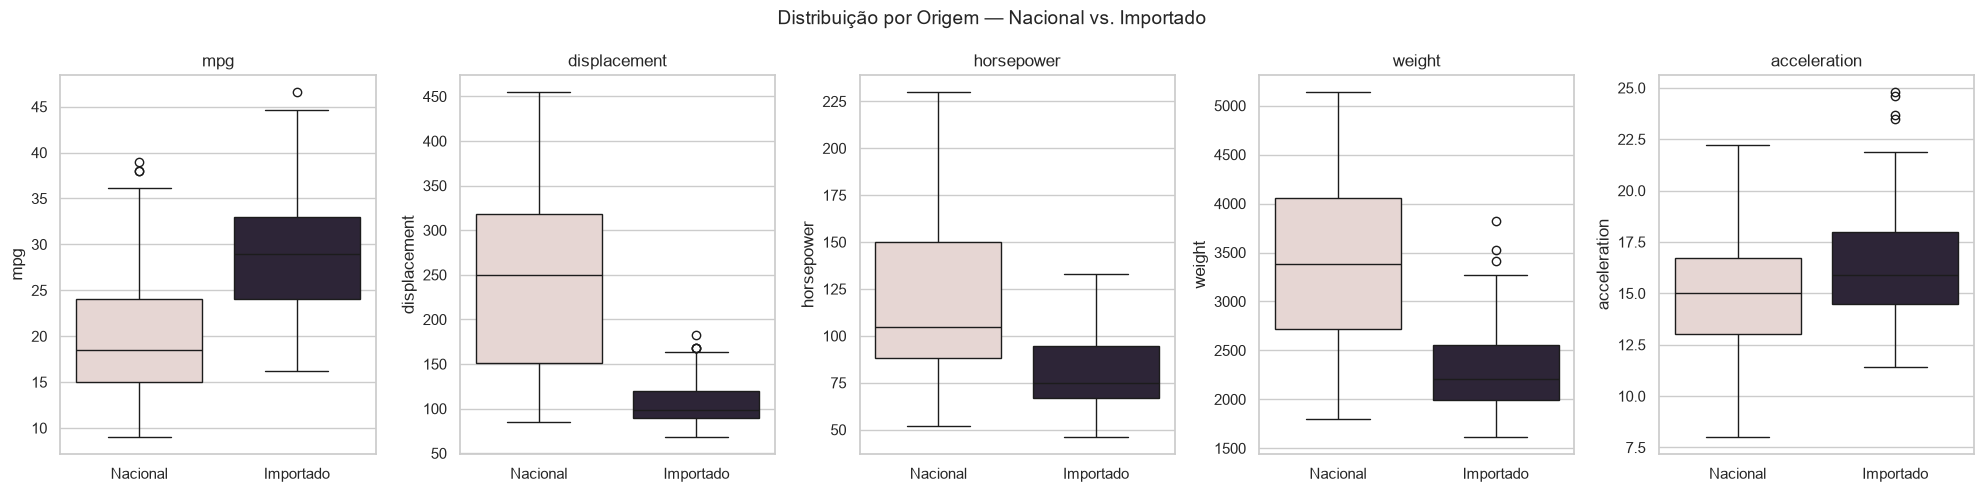

In [22]:
import numpy as np

df["origem"] = np.where(df["origin"] == 1, "Nacional", "Importado")
palette_classe = {"Nacional": "#e9d4d0", "Importado": "#2d223a"}

fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 5), sharex=False)

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, x="origem", y=col, hue="origem",
                palette=palette_classe, legend=False, ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel("")

fig.suptitle("Distribuição por Origem — Nacional vs. Importado", fontsize=14)
plt.tight_layout()
plt.show()

**Discussão:** a separação mais nítida é em `mpg`, `displacement` e `weight`. A mediana de `mpg` é 18,5 nos nacionais contra 29,0 nos importados; `weight` é 3381 lb vs. 2210 lb; `displacement` é 250 vs. 98. Isso é totalmente coerente com o senso comum sobre o mercado americano dos anos 70/80 (carros maiores, motores maiores, menos econômicos) — e com a correlação forte encontrada logo abaixo entre `weight`/`displacement` e `mpg`. `acceleration` é a que menos separa as duas classes (15,0 vs. 15,9), sugerindo que a origem por si só não é um bom preditor de aceleração.

### Análise bivariada: quantitativa × quantitativa

Como nenhuma variável passou no Shapiro-Wilk, uso **Spearman** (relação monotônica, não exige normalidade) em vez de Pearson.

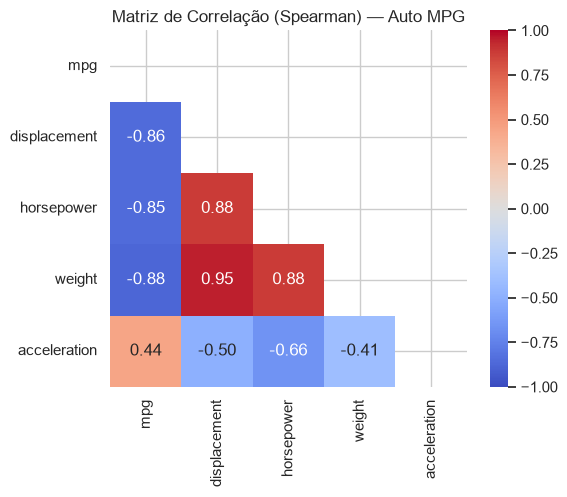

In [23]:
corr_spearman = df[VARS_QUANT].corr(method="spearman")

mask = np.triu(np.ones_like(corr_spearman, dtype=bool))
plt.figure(figsize=(6, 5))
sns.heatmap(corr_spearman, mask=mask, annot=True, cmap="coolwarm", fmt=".2f", square=True, vmin=-1, vmax=1)
plt.title("Matriz de Correlação (Spearman) — Auto MPG")
plt.tight_layout()
plt.show()

**Discussão:** `mpg` correlaciona fortemente (|r| > 0,7) e negativamente com `weight` (-0,88), `displacement` (-0,86) e `horsepower` (-0,85): carro maior/mais potente consome mais, na direção esperada. Mas essas três também correlacionam fortemente **entre si** (`weight`×`displacement` = 0,95; `weight`×`horsepower` = 0,88; `displacement`×`horsepower` = 0,88) — um indício claro de multicolinearidade (elas "andam juntas", provavelmente porque motores maiores exigem carroceria/estrutura maior). Isso é relevante para qualquer modelagem futura: usar as três como preditoras independentes seria redundante. `acceleration` é a mais fraca (0,44 com `mpg`), coerente com o boxplot da seção anterior, onde ela quase não diferenciava nacionais de importados.

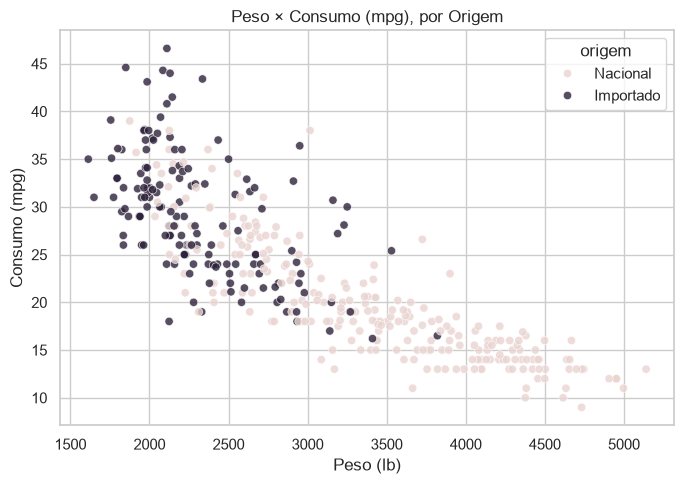

In [24]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="weight", y="mpg", hue="origem",
                 palette=palette_classe, alpha=0.8)
plt.title("Peso × Consumo (mpg), por Origem")
plt.xlabel("Peso (lb)")
plt.ylabel("Consumo (mpg)")
plt.tight_layout()
plt.show()

**Discussão:** a tendência negativa (peso ↑ → consumo ↓) é bem visível e consistente com a correlação de -0,88. As duas classes não formam blocos totalmente separados — há sobreposição na faixa intermediária de peso —, mas os nacionais (rosa) se concentram claramente mais à direita/embaixo (carros mais pesados e menos econômicos) e os importados (roxo) mais à esquerda/em cima, reforçando a leitura dos boxplots por origem.

---
> 🆕 **NOVA SEÇÃO (adaptada do `eda-com-downloads.ipynb` da aula)** — as 4 células abaixo (esta, mais 3) servem apenas para salvar os datasets em disco.

## 🆕 Download dos Datasets

Vamos salvar duas versões do dataset:

- `data/raw/dataset.csv`: o dataset **original**, como veio da UCI (`auto_mpg.data.original`, sem a coluna `origem`, sem remoção de linhas).
- `data/clean/dataset.csv`: o dataset **tratado**, no estado final do `df` ao longo da EDA (6 linhas com `horsepower` ausente removidas e coluna `origem` criada). É este arquivo que o `app.py` lê.

> Rode o notebook **do início ao fim** antes desta seção, para que o `df` esteja no estado final.

In [25]:
# 🆕 NOVA CÉLULA — define as pastas de destino (funciona rodando de notebooks/ ou da raiz do projeto)
from pathlib import Path

RAIZ = Path("..") if Path("../data").exists() else Path(".")
PASTA_RAW = RAIZ / "data" / "raw"
PASTA_CLEAN = RAIZ / "data" / "clean"
PASTA_RAW.mkdir(parents=True, exist_ok=True)
PASTA_CLEAN.mkdir(parents=True, exist_ok=True)

In [26]:
# 🆕 NOVA CÉLULA — dataset ORIGINAL (reconstruído a partir do objeto `auto_mpg`, que não foi alterado)
df_raw = auto_mpg.data.original.copy()
df_raw.to_csv(PASTA_RAW / "dataset.csv", index=False)

print(f"Raw salvo em {PASTA_RAW / 'dataset.csv'} — {df_raw.shape[0]} linhas x {df_raw.shape[1]} colunas")

Raw salvo em ..\data\raw\dataset.csv — 398 linhas x 9 colunas


In [27]:
# 🆕 NOVA CÉLULA — dataset TRATADO (estado final do `df`)
df.to_csv(PASTA_CLEAN / "dataset.csv", index=False)

print(f"Clean salvo em {PASTA_CLEAN / 'dataset.csv'} — {df.shape[0]} linhas x {df.shape[1]} colunas")
print(f"Linhas removidas no tratamento: {df_raw.shape[0] - df.shape[0]}")

Clean salvo em ..\data\clean\dataset.csv — 392 linhas x 10 colunas
Linhas removidas no tratamento: 6


## Síntese e Conclusões

1. **Estrutura:** 398 linhas, 9 colunas; só `horsepower` tinha ausentes (6 linhas, ~1,5%), removidas após identificar mecanismo provável MAR/MCAR (ausências espalhadas entre categorias, sem concentração). Nenhuma duplicada verdadeira.
2. **Distribuição:** `horsepower`, `displacement` e `weight` são assimétricas à direita (skewness entre 0,5 e 1,1); todas as 5 variáveis quantitativas rejeitam normalidade no Shapiro-Wilk (p < 0,05), inclusive `acceleration`, que era a mais simétrica visualmente.
3. **Outliers:** concentrados em `horsepower` (10) e `acceleration` (7), classificados como estatísticos/legítimos (motores e tempos de aceleração raros, mas mecanicamente plausíveis para carros de 1970-82) — mantidos sem transformação.
4. **Relação peso ↔ consumo:** correlação forte e negativa (Spearman = -0,88); junto com `displacement` (-0,86) e `horsepower` (-0,85), essas três variáveis também são fortemente correlacionadas entre si (multicolinearidade), sugerindo redundância para uma futura modelagem.
5. **Origem do carro:** nacionais (EUA) têm mediana de consumo bem menor (18,5 vs. 29,0 mpg), carros mais pesados (3381 vs. 2210 lb) e motores maiores (250 vs. 98 pol³) que os importados — coerente com o perfil histórico do mercado americano dos anos 70/80. `acceleration` é a variável que menos diferencia as duas origens.

## Declaração de Uso de IA

| Item | Descrição |
|---|---|
| **Ferramenta utilizada** | Claude (Anthropic), via Claude Code |
| **Para o que foi aplicada** | Acompanhamento do desenvolvimento do notebook a partir da seção de Princípio Estrutural já existente: implementação das seções de Princípio Distribucional, Tratamento de Dados Ausentes e Outliers, Princípio Relacional (análise bivariada) e Síntese, adaptando ao dataset Auto MPG a estrutura e as técnicas demonstradas no notebook "Aula 11 - EDA na Prática" (Classroom). |
| **O que foi aceito** | A divisão em seções, as escolhas de gráfico (histograma+KDE, boxplot, heatmap de correlação, scatter), a função `limites_iqr`, e os textos de discussão — escritos com base nos números efetivamente calculados neste dataset (não copiados do notebook de demonstração). |
| **O que foi modificado** | Simplifiquei a análise de desbalanceamento (fiz frequências, mas sem as métricas de entropia do notebook de demonstração) e omiti a execução/interpretação formal dos testes de hipótese (Mann-Whitney, ANOVA/Kruskal-Wallis, Qui-quadrado), conforme indicado como opcional no enunciado da atividade e reforçado no comentário da profa. Maira. |
| **O que foi rejeitado e por quê** | Não repliquei a seção de *fairness* (proporção de eficiência por origem/época) do notebook de demonstração — não é exigida no enunciado desta entrega e alongaria o notebook sem necessidade. Também não removi os outliers (mantidos, por serem estatisticamente legítimos, não erros de coleta). |